# 01 — data exploration

first look at the California Housing dataset. goal is to understand the data before touching it.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_california

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

## load data

In [2]:
df = load_california()
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


**what the columns mean:**

| column | description |
|--------|-------------|
| `MedInc` | median income in block group (in $10,000s) |
| `HouseAge` | median house age in block group |
| `AveRooms` | average number of rooms per household |
| `AveBedrms` | average number of bedrooms per household |
| `Population` | block group population |
| `AveOccup` | average number of household members |
| `Latitude` | block group latitude |
| `Longitude` | block group longitude |
| `price` | median house value (in $100,000s) — **target** |

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
df.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


## missing values

In [5]:
df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
price         0
dtype: int64

no missing values. California Housing is clean out of the box.

## target distribution

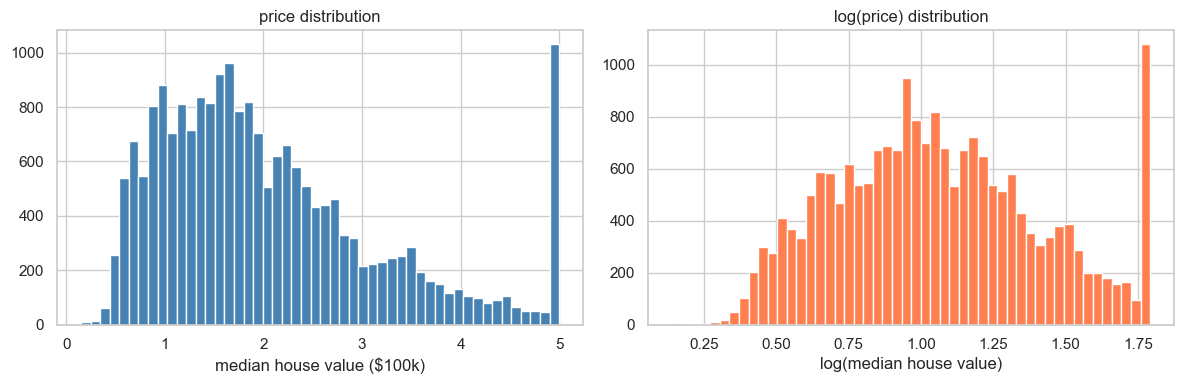

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['price'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('price distribution')
axes[0].set_xlabel('median house value ($100k)')

axes[1].hist(np.log1p(df['price']), bins=50, color='coral', edgecolor='white')
axes[1].set_title('log(price) distribution')
axes[1].set_xlabel('log(median house value)')

plt.tight_layout()
plt.savefig('../plots/target_distribution.png', dpi=120)
plt.show()

the price is slightly right-skewed and capped at 5.0 (looks like the dataset clips high values). log transform makes it more normal.

## correlation heatmap

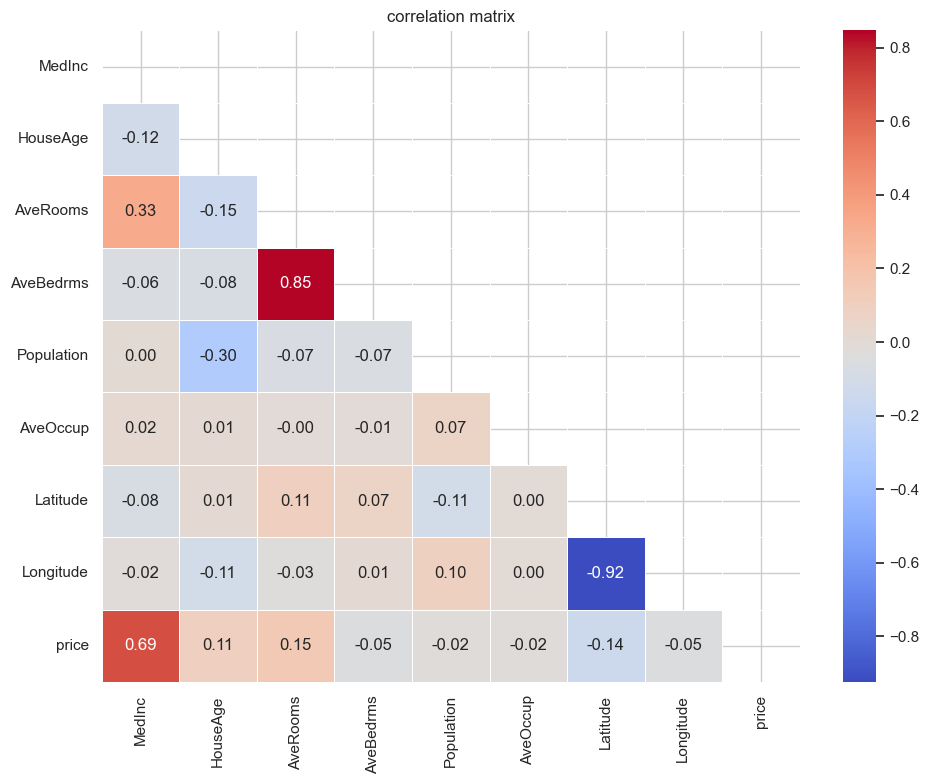

In [7]:
plt.figure(figsize=(10, 8))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('correlation matrix')
plt.tight_layout()
plt.savefig('../plots/correlation_heatmap.png', dpi=120)
plt.show()

**takeaways:**
- `MedInc` has the strongest correlation with price (0.69) — makes sense
- `AveRooms` and `AveBedrms` are highly correlated with each other — might be redundant
- `Latitude` and `Longitude` have non-trivial correlation — location matters a lot in California

## median income vs price

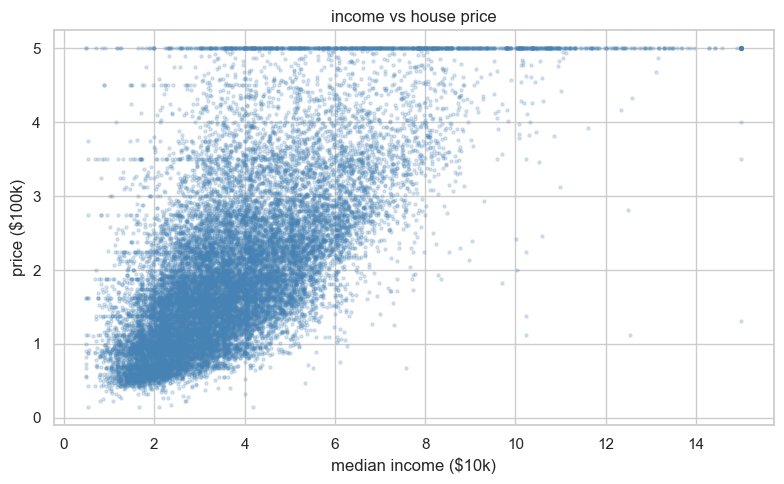

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(df['MedInc'], df['price'], alpha=0.2, s=5, color='steelblue')
plt.xlabel('median income ($10k)')
plt.ylabel('price ($100k)')
plt.title('income vs house price')
plt.tight_layout()
plt.savefig('../plots/income_vs_price.png', dpi=120)
plt.show()

## geographic distribution

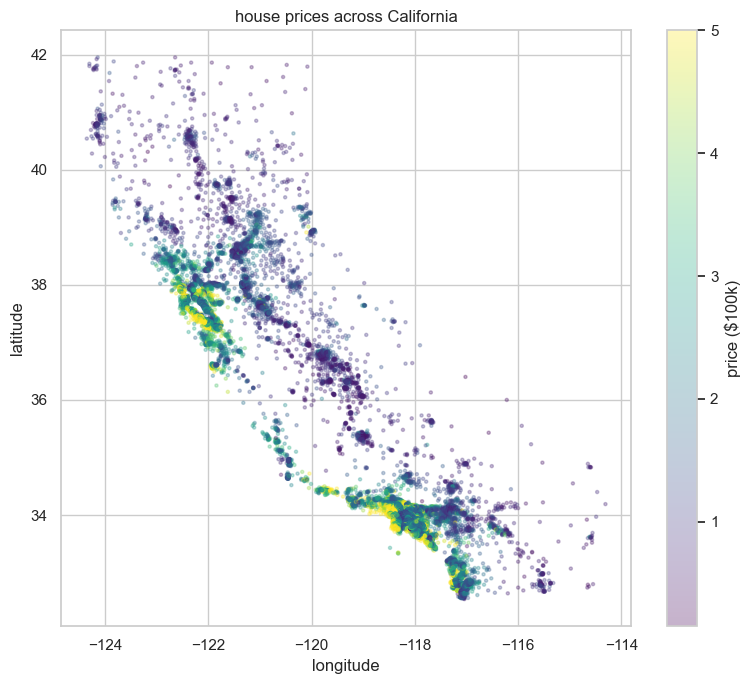

In [9]:
plt.figure(figsize=(8, 7))
sc = plt.scatter(
    df['Longitude'], df['Latitude'],
    c=df['price'], cmap='viridis', alpha=0.3, s=5
)
plt.colorbar(sc, label='price ($100k)')
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.title('house prices across California')
plt.tight_layout()
plt.savefig('../plots/geo_distribution.png', dpi=120)
plt.show()

coastal areas (SF, LA) are clearly more expensive. this suggests lat/lon will be useful features.

## feature distributions

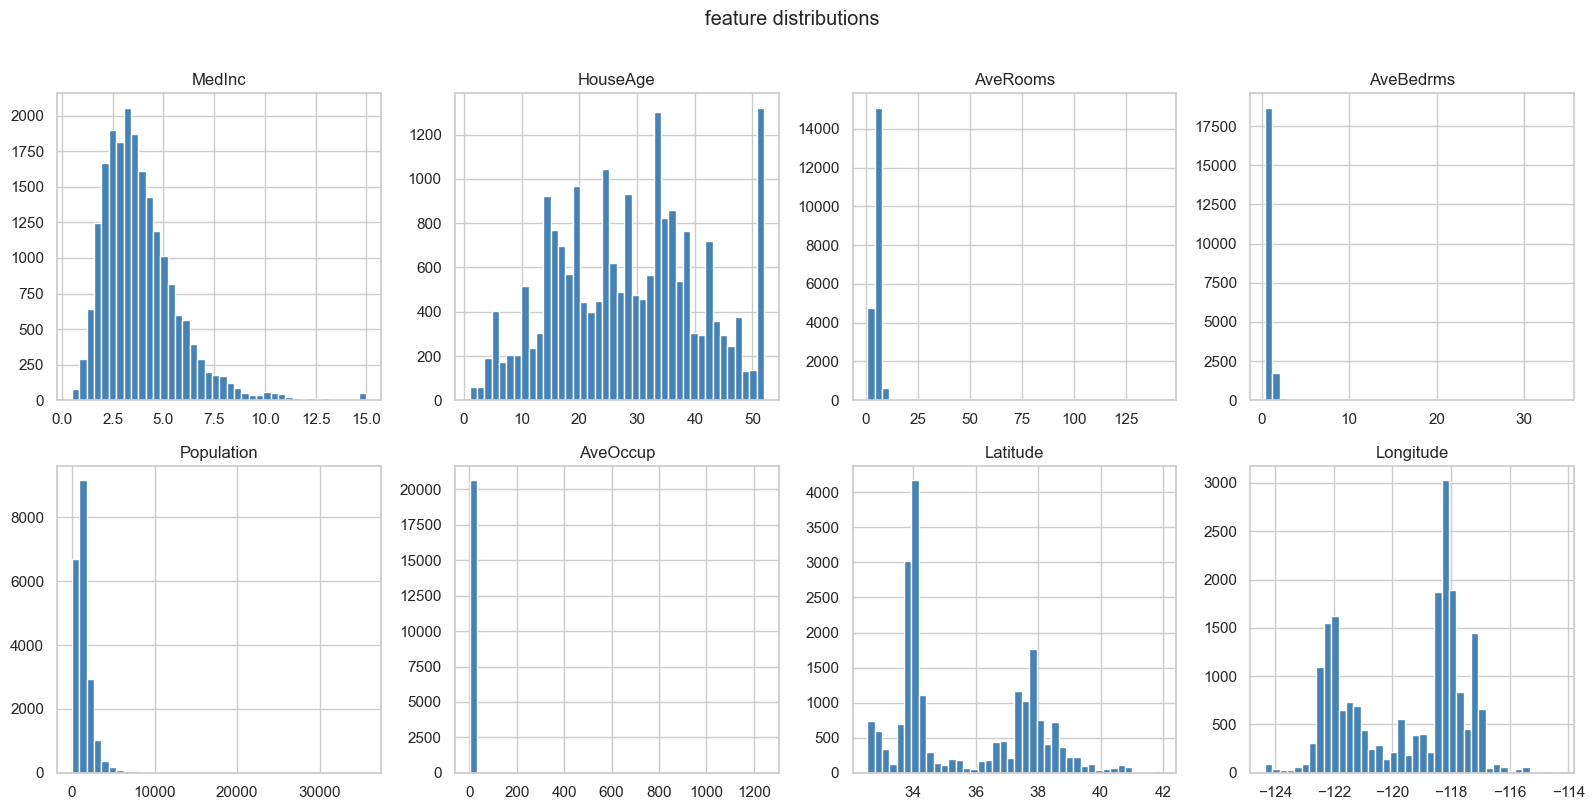

In [10]:
features = [c for c in df.columns if c != 'price']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].hist(df[col], bins=40, color='steelblue', edgecolor='white')
    axes[i].set_title(col)

plt.suptitle('feature distributions', y=1.01)
plt.tight_layout()
plt.savefig('../plots/feature_distributions.png', dpi=120)
plt.show()

**AveRooms**, **AveBedrms**, **Population**, and **AveOccup** are all right-skewed — will need log transforms.